# Análisis ConnectaTel

Como **analista de datos**, tu objetivo es evaluar el **comportamiento de los clientes** de una empresa de telecomunicaciones en Latinoamérica, ConnectaTel. 

Trabajaremos con información registrada **hasta el año 2024**, lo cual permitirá analizar el comportamiento del negocio dentro de ese periodo.

Para ello trabajarás con tres datasets:  

- **plans.csv** → información de los planes actuales (precio, minutos incluidos, GB incluidos, costo por extra)  
- **users.csv** → información de los clientes (edad, ciudad, fecha de registro, plan, churn)  
- **usage.csv** → detalle del **uso real** de los servicios (llamadas y mensajes)  

Deberás **explorar**, **limpiar** y **analizar** estos datos para construir un **perfil estadístico** de los clientes, detectar **comportamientos atípicos** y crear **segmentos de clientes**.  

Este análisis te permitirá **identificar patrones de consumo**, **diseñar estrategias de retención** y **sugerir mejoras en los planes** ofrecidos por la empresa.

> 💡 Antes de empezar, recuerda pensar de forma **programática**: ¿qué pasos necesitas? ¿En qué orden? ¿Qué quieres medir y por qué?


--- 
## 🧩 Paso 1: Cargar y explorar

Antes de limpiar o combinar los datos, es necesario **familiarizarte con la estructura de los tres datasets**.  
En esta etapa, validarás que los archivos se carguen correctamente, conocerás sus columnas y tipos de datos, y detectarás posibles inconsistencias.

### 1.1 Carga de datos y vista rápida

**🎯 Objetivo:**  
Tener los **3 datasets listos en memoria**, entender su contenido y realizar una revisión preliminar.

**Instrucciones:**  
- Importa las librerías necesarias (por ejemplo `pandas`, `seaborn`, `matplotlib.pyplot`)
- Carga los archivos CSV usando `pd.read_csv()`:
  - **`/datasets/plans.csv`**  
  - **`/datasets/users_latam.csv`**  
  - **`/datasets/usage.csv`**  
- Guarda los DataFrames en las variables: `plans`, `users`, `usage`.  
- Muestra las primeras filas de cada DataFrame usando `.head()`.


In [2]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# cargar archivos
plans = pd.read_csv('/datasets/plans.csv')
users = pd.read_csv('/datasets/users_latam.csv')
usage = pd.read_csv('/datasets/usage.csv')

In [4]:
display(plans.head(5))

,plan_name,messages_included,gb_per_month,minutes_included,usd_monthly_pay,usd_per_gb,usd_per_message,usd_per_minute
0,Basico,100,5,100,12,1.2,0.08,0.10
1,Premium,500,20,600,25,1.0,0.05,0.07


In [5]:
display(users.head(5))

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN


In [6]:
display(usage.head(5))

,id,user_id,type,date,duration,length
0,1,10332,call,2024-01-01 00:00:00.000000000,0.09,NaN
1,2,11458,text,2024-01-01 00:06:30.969774244,NaN,39.0
2,3,11777,text,2024-01-01 00:13:01.939548488,NaN,36.0
3,4,10682,call,2024-01-01 00:19:32.909322733,1.53,NaN
4,5,12742,call,2024-01-01 00:26:03.879096977,4.84,NaN


**Tip:** Si no usas `print()` la tabla se vera mejor.

### 1.2 Exploración de la estructura de los datasets

**🎯 Objetivo:**  
Conocer la **estructura de cada dataset**, revisar cuántas filas y columnas tienen, identificar los **tipos de datos** de cada columna y detectar posibles **inconsistencias o valores nulos** antes de iniciar el análisis.

**Instrucciones:**  
- Revisa el **número de filas y columnas** de cada dataset usando `.shape`.  
- Usa `.info()` en cada DataFrame para obtener un **resumen completo** de columnas, tipos de datos y valores no nulos.  

In [7]:
# revisar el número de filas y columnas de cada dataset


print("plans", plans.shape)
print("users", users.shape)
print("usage", usage.shape)



plans (2, 8)
users (4000, 8)
usage (40000, 6)


In [8]:
plans.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   plan_name          2 non-null      object 
 1   messages_included  2 non-null      int64  
 2   gb_per_month       2 non-null      int64  
 3   minutes_included   2 non-null      int64  
 4   usd_monthly_pay    2 non-null      int64  
 5   usd_per_gb         2 non-null      float64
 6   usd_per_message    2 non-null      float64
 7   usd_per_minute     2 non-null      float64
dtypes: float64(3), int64(4), object(1)
memory usage: 256.0+ bytes


In [9]:
users.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4000 entries, 0 to 3999
Data columns (total 8 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   user_id     4000 non-null   int64 
 1   first_name  4000 non-null   object
 2   last_name   4000 non-null   object
 3   age         4000 non-null   int64 
 4   city        3531 non-null   object
 5   reg_date    4000 non-null   object
 6   plan        4000 non-null   object
 7   churn_date  466 non-null    object
dtypes: int64(2), object(6)
memory usage: 250.1+ KB


In [10]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 40000 entries, 0 to 39999
Data columns (total 6 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   id        40000 non-null  int64  
 1   user_id   40000 non-null  int64  
 2   type      40000 non-null  object 
 3   date      39950 non-null  object 
 4   duration  17924 non-null  float64
 5   length    22104 non-null  float64
dtypes: float64(2), int64(2), object(2)
memory usage: 1.8+ MB


---

## 🧩Paso 2: Identificación de problemas de calidad de datos

### 2.1 Revisión de valores nulos

**🎯 Objetivo:**  
Detectar la presencia y magnitud de valores faltantes para evaluar si afectan el análisis o requieren imputación/eliminación.

**Instrucciones:**  
- Cuenta valores nulos por columna para cada dataset.
- Calcula la proporción de nulos por columna para cada dataset.

El dataset `plans` solamente tiene 2 renglones y se puede observar que no tiene ausentes, por ello no necesita exploración adicional.

<br>
<details>
<summary>Haz clic para ver la pista</summary>
Usa `.isna().sum()` para contar valores nulos y usa `.isna().mean()` para calcular la proporción.

In [11]:



# cantidad de nulos para users
print("Cantidad de valores nulos:")
print(users.isna().sum())

print("\nProporción de valores nulos:")
print(users.isna().mean())



Cantidad de valores nulos:
user_id          0
first_name       0
last_name        0
age              0
city           469
reg_date         0
plan             0
churn_date    3534
dtype: int64

Proporción de valores nulos:
user_id       0.00000
first_name    0.00000
last_name     0.00000
age           0.00000
city          0.11725
reg_date      0.00000
plan          0.00000
churn_date    0.88350
dtype: float64


In [12]:

# cantidad de nulos para users
print("Cantidad de valores nulos:")
print(usage.isna().sum())

print("\nProporción de valores nulos:")
print(usage.isna().mean())


Cantidad de valores nulos:
id              0
user_id         0
type            0
date           50
duration    22076
length      17896
dtype: int64

Proporción de valores nulos:
id          0.00000
user_id     0.00000
type        0.00000
date        0.00125
duration    0.55190
length      0.44740
dtype: float64


In [13]:
**Valores nulos**

- `churn_date` (`users`): Presenta un 83.35% de nulos. Se ignora o elimina (o se mantiene sin imputar), ya que la gran mayoría de los usuarios siguen activos con su servicio y no han cancelado.
- `city` (`users`): Presenta un 11.73% de nulos. Se investiga para imputar por la moda o dejar como categoría desconocida.
- `date` (`usage`): Presenta un 0.13%de nulos. Al ser menor al 5%, es un caso simple donde se pueden eliminar las filas o imputar según la fecha de registro.
- `duration` y `length` (`usage`): Presentan 55.19% y 44.74% de nulos respectivamente. Se investiga la naturaleza del dato (eje: si los nulos en `duration` corresponden a mensajes de texto donde no hay minutos consumidos) para tratarlos o dejarlos como nulos según el tipo de servicio.

SyntaxError: invalid syntax (1256887676.py, line 1)

### 2.2 Detección de valores inválidos y sentinels

🎯 **Objetivo:**  
Identificar sentinels: valores que no deberían estar en el dataset.

**Instrucciones:**
- Explora las columnas numéricas con **un resumen estadístico** y describe brevemente que encontraste.
- Explora las columnas categóricas **relevantes**, revisando sus valores únicos y describe brevemente que encontraste.


El dataset `plans` solamente tiene 2 renglones, por ello no necesita exploración adicional.

In [1]:
users.describe()

NameError: name 'users' is not defined



- La columna user_id: Funciona como el identificador único de cada usuario, con un rango que va desde 10,000 hasta 13,999  sin valores atípicos.
- La columna age: Presenta un problema crítico en el valor mínimo (-999), lo cual evidencia un valor inválido que distorsiona la estadística como la media y la desviación estándar. Sacando eso, las edades se distribuyen en un rango lógico hasta 79 años

In [ ]:
usage.describe()


Las columnas id y user_id: Muestran identificadores correctos, donde user_id vincula adecuadamente las acciones de uso con el catálogo de usuarios.  
Las columnas duration  y length: Presentan valores mínimos de 0 y un conteo significativamente menor al total de registros (17,924 y 22,104 frente a los 40,000 esperados), lo cual evidencia la presencia de valores nulos que deberán ser tratados.

In [ ]:
# explorar columnas categóricas de users
columnas_user = ['city', 'plan']

for col in columnas_user:
    print(f"\nValores únicos en '{col}':")
    display(users[col].value_counts(dropna=False))


- La columna city: Presenta valores válidos para varias ciudades (Bogotá, CDMX, Medellín, GDL, Cali, MTY), pero contiene 469 valores nulos  y 96 valores con este signo "?", lo que indica datos faltantes o no registrados.
-  La columna plan: Está limpia y bien estructurada, dividida únicamente en dos categorías válidas.

In [ ]:

# explorar columna categórica de usage
usage['type'].value_counts(dropna=False)


- La columna `type muestra una distribución consistente sin valores nulos ni centinelas, dividida únicamente entre text (22092) y call (17908).


---
✍️ **Comentario**: Haz doble clic en este bloque y escribe tu diagnóstico. Incluye qué ves y que acción recomendarías para cada caso. 

**Valores inválidos o sentinels**  
- ¿En qué columnas encontraste valores inválidos o sentinels?:en users  encontammos una categoria de nulos de 469 y 96 valores atipicos en usage no se encontraron alteraciones de este tipo.
- ¿Qué acción tomarías?: podriamos remplazar el valor atipico de age por la mediana para que sean mas consistentes los datos,los valosres de city que aparecen con el signo ? y son 96 podriamos dejarlos como desconocidos. 

### 2.3 Revisión y estandarización de fechas

**🎯 Objetivo:**  
Asegurar que las columnas de fecha estén correctamente formateadas y detectar años fuera de rango que indiquen errores de captura.

**Instrucciones:**  
- Convierte las columnas de fecha a tipo fecha y asegurate de que el código sea a prueba de errores.  
- Revisa cuántas veces aparece cada año.
- Identifica fechas imposibles (ej. años futuros o negativos).

Toma en cuenta que tenemos datos registrados hasta el año 2024.

In [ ]:
# Convertir a fecha la columna `reg_date` de users
users['reg_date'] = pd.to_datetime(users['reg_date'])

In [ ]:
# Convertir a fecha la columna `date` de usage
usage['date'] = pd.to_datetime(usage['date'])

In [ ]:
# Revisar los años presentes en `reg_date` de users
print(users['reg_date'].dt.year.value_counts(dropna=False))

En `reg_date`, ... haz doble clic en este bloque y escribe qué ves.

In [ ]:
# Revisar los años presentes en `date` de usage
print(usage['date'].dt.year.value_counts(dropna=False))

En `date`, ... haz doble clic en este bloque y escribe qué ves.  
Basaremos el análisis en estas fechas.

✍️ **Comentario**: escribe tu diagnóstico, e incluye **qué acción recomendarías** para cada caso:
- reg_date Se observa que la mayoría de los registros se concentran entre 2022 y 2024, pero aparecen 40 registros con el año 2026, los cuales corresponden a fechas futuras erróneas
date, La mayoría de los registros de uso pertenecen al año 2024 39,950 , además de 50 valores nulos (NaN) que no tienen fecha asignada
**Fechas fuera de rango**    
- ¿Aparecen años imposibles? (años muy viejos o sin transcurrir al momento de guardar los datos): 
  Sí, en la columna `reg_date` aparecen registros con el año 2026, el cual supera el límite establecido de 2024.
- **¿Qué harías con ellas?**: 
  Marcar las fechas futuras mayores al año 2024 y los valores nulos como `pd.NaT`  para que no afecten los cálculos temporales futuros.

---

## 🧩Paso 3: Limpieza básica de datos

### 3.1 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Aplicar reglas de limpieza para reemplazar valores sentinels y corregir fechas imposibles.

**Instrucciones:**  
- En `age`, reemplaza el sentinel **-999** con la mediana.
- En `city`, reemplaza el sentinel `"?"` por valores nulos (`pd.NA`).  
- Marca como nulas (`pd.NA`) las fechas fuera de rango.

In [ ]:
# Reemplazar -999 por la mediana de age
age_mediana = users[users['age'] != -999]['age'].median()
users['age'] = users['age'].replace(-999, age_mediana)

# Verificar cambios
users['age'].describe()

In [ ]:




# Reemplazar ? por NA en city
users['city'] = users['city'].replace('?', pd.NA)

# Verificar cambios
print(users['city'].value_counts(dropna=False))

In [ ]:

# Marcar fechas mayores al año 2026 como nulas (NaT) de forma segura
users['reg_date'] = users['reg_date'].where(users['reg_date'].dt.year <= 2026, pd.NaT)

# Verificar cambios
print(users['reg_date'].dt.year.value_counts(dropna=False))

### 3.2 Corregir sentinels y fechas imposibles
**🎯 Objetivo:**  
Decidir qué hacer con los valores nulos según su proporción y relevancia.

**Instrucciones:**
- Verifica si los nulos en `duration` y `length` son **MAR**(Missing At Random) revisando si dependen de la columna `type`.  
  Si confirmas que son MAR, **déjalos como nulos** y justifica la decisión.

In [ ]:
# Verificación MAR en usage (Missing At Random) para duration
# Crear una columna temporal que indique si es nulo en duration y analizarlo con el tipo de uso u otras variables
usage['duration_is_null'] = usage['duration'].isna()
print(usage.groupby('type')['duration_is_null'].mean())

In [ ]:
# Verificación MAR en usage (Missing At Random) para length
# Crear una columna temporal que indique si es nulo en length y analizarlo
usage['length_is_null'] = usage['length'].isna()
print(usage.groupby('type')['length_is_null'].mean())

Haz doble clic aquíy escribe que tu diagnostico de nulos en `duration` y `length`
-Para duration duración: La probabilidad de que sea nulo es de 0.00 (0%) cuando es una llamada (call), pero sube al 0.999 (100%) cuando se trata de un mensaje de texto (text).

Para length longitud: Ocurre exactamente lo contrario; la probabilidad de ser nulo es de 0.999 (100%) en las llamadas call y de 0.00 (0%) en los mensajes de texto (text).

---

## 🧩Paso 4: Summary statistics de uso por usuario


### 4.1 Agrupación por comportamiento de uso

🎯**Objetivo**: Resumir las variables clave de la tabla `usage` **por usuario**, creando métricas que representen su comportamiento real de uso histórico. 

**Instrucciones:**: 
1. Construye una tabla agregada de `usage` por `user_id` que incluya:
- número total de mensajes  
- número total de llamadas  
- total de minutos de llamadas

2. Renombra las columnas para que tengan nombres claros:  
- `cant_mensajes`  
- `cant_llamadas`  
- `cant_minutos_llamada`
3. Combina esta tabla con `users`.

In [ ]:
# Ver qué columnas tenemos disponibles exactamente en usage
print("Columnas en usage:", usage.columns.tolist())

# Agrupar usando solo las columnas numéricas reales de uso (excluyendo id y user_id)
cols_a_sumar = [col for col in usage.columns if col not in ['id', 'user_id', 'date', 'type']]
usage_agg = usage.groupby("user_id")[cols_a_sumar].sum().reset_index()

# Observar resultado
usage_agg.head(3)

In [ ]:

usage['is_text'] = (usage['type'] == 'text').astype(int)
usage['is_call'] = (usage['type'] == 'call').astype(int)

# Agrupar y sumar
usage_agg = usage.groupby("user_id")[["is_text", "is_call", "duration"]].sum().reset_index()

usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",

    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})

# Observar resultado
usage_agg.head(3)

In [ ]:

# Combinar la tabla agregada con el dataset de usuarios
user_profile = users.merge(usage_agg, on="user_id", how="left")

# observar resultado
user_profile.head(5)

### 4.2 4.2 Resumen estadístico por usuario durante el 2024

🎯 **Objetivo:** Analizar las columnas numéricas y categóricas de los usuarios, para identificar rangos, valores extremos y distribución de los datos antes de continuar con el análisis.

**Instrucciones:**  
1. Para las columnas **numéricas** relevantes, obtén un resumen estadístico (media, mediana, mínimo, máximo, etc.).  
2. Para la columna **categórica** `plan`, revisa la distribución en **porcentajes** de cada categoría.

In [ ]:
# Resumen estadístico de las columnas numéricas
# Resumen estadístico de las columnas numéricas relevantes
user_profile.describe()

In [ ]:
# Distribución porcentual del tipo de plan
# Distribución porcentual del tipo de plan
print(user_profile['plan'].value_counts(normalize=True) * 100)

---

## 🧩Paso 5: Visualización de distribuciones (uso y clientes) y outliers


### 5.1 Visualización de Distribuciones

🎯 **Objetivo:**  
Entender visualmente cómo se comportan las variables clave tanto de **uso** como de **clientes**, observar si existen diferencias según el tipo de plan, y analizar la **forma de la distribución**.

**Instrucciones:**  
Graficar **histogramas** para las siguientes columnas:  
- `age` (edad de los usuarios)
- `cant_mensajes`
- `cant_llamadas`
- `total_minutos_llamada` 

Después de cada gráfico, escribe un **insight** respecto al plan y la variable, por ejemplo:  
- "Dentro del plan Premium, hay mayor proporción de..."  
- "Los usuarios Básico tienden a hacer ... llamadas y enviar ... mensajes."  o "No existe algún patrón."
- ¿Qué tipo de distribución tiene ? (simétrica, sesgada a la derecha o a la izquierda) 

**Hint**  
Para cada histograma, 
- Usa `hue='plan'` para ver cómo varían las distribuciones según el plan (Básico o Premium).
- Usa `palette=['skyblue','green']`
- Agrega título y etiquetas

In [ ]:

# 1. Primero filtramos las edades válidas (mayores o iguales a 0)
user_profile_clean = user_profile[user_profile['age'] >= 0]

# 2. Luego graficamos usando el dataset limpio 'user_profile_clean'
sns.histplot(data=user_profile_clean, x='age', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Distribución de la Edad por Tipo de Plan')
plt.xlabel('Edad')
plt.ylabel('Frecuencia')
plt.show()



💡Insights: 
- **Distribución de la edad**: lo promero que se corrigio fue el valor centinela que teniamos en edad donde -999.000 nos podia modificar la informacion, ahora tenemos  una distribución ligeramente sesgada a la derecha, donde la mayoría de los usuarios se concentran en rangos de edad jóvenes y adultos aproximadamente entre 30 y 50 años.
- **Relación con el plan**: La proporción de usuarios con plan Básico(celeste) y Premium (verde) mantiene un comportamiento muy similar en todas las edades, sin que se aprecie una preferencia.

In [ ]:

# Unir la tabla de perfiles de usuario con las métricas agregadas de uso
user_profile = users.merge(usage_agg, on='user_id', how='left')

# Histograma para visualizar la cant_mensajes
sns.histplot(data=user_profile, x='cant_mensajes', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Distribución de Cantidad de Mensajes por Plan')
plt.xlabel('Cantidad de Mensajes')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- - **Distribución de la cantidad de mensajes**: Presenta una distribución ligeramente sesgada a la derecha,con un pico claro de frecuencia alrededor de los 5 y 6 mensajes enviados por usuario.
- **Relación con el plan**: Se observa que los usuarios con plan **Básico** (celeste) registran una mayor frecuencia total en comparación con los usuarios **Premium** (verde), lo cual es coherente con la proporción de cada tipo de usuario en el dataset, manteniendo proporciones similares de uso entre ambos planes.

In [ ]:
# Histograma para visualizar la cant_llamadas
# Histograma para visualizar la cant_llamadas
sns.histplot(data=user_profile, x='cant_llamadas', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Distribución de Cantidad de Llamadas por Plan')
plt.xlabel('Cantidad de Llamadas')
plt.ylabel('Frecuencia')
plt.show()

💡Insights:  **Distribución de la cantidad de llamadas**: Presenta una distribución simétrica o con ligera asimetría , concentrando la mayor frecuencia de llamadas entre 3 y 5 eventos por usuario.
- **Relación con el plan**: Los usuarios con plan **Básico** (celeste) muestran una frecuencia total mayor debido al volumen de su categoría, pero ambos tipos de planes comparten una tendencia de uso muy similar, sin diferencias estructurales drásticas en la cantidad de llamadas realizadas.

In [ ]:
# Histograma para visualizar la cant_minutos_llamada
# Histograma para visualizar la cant_minutos_llamada
sns.histplot(data=user_profile, x='cant_minutos_llamada', hue='plan', palette=['skyblue', 'green'], kde=True, multiple='dodge')
plt.title('Distribución de Minutos de Llamada por Plan')
plt.xlabel('Minutos de Llamada')
plt.ylabel('Frecuencia')
plt.show()

💡Insights: 
- - Distribución de los minutos de llamada: Presenta una distribución sesgada a la derecha , con una alta concentración de usuarios que consumen entre 15 y 20 minutos de llamada en total, disminuyendo progresivamente a medida que aumentan los minutos consumidos.
- Relación con el plan: Al igual que en las métricas anteriores, el plan Básico (celeste) acumula mayor frecuencia total que el plan Premium (verde) debido al tamaño de su grupo, pero ambos tipos de planes siguen exactamente la misma tendencia de consumo temporal.

### 5.2 Identificación de Outliers

🎯 **Objetivo:**  
Detectar valores extremos en las variables clave de **uso** y **clientes** que podrían afectar el análisis, y decidir si requieren limpieza o revisión adicional.

**Instrucciones:**  
- Usa **boxplots** para identificar visualmente outliers en las siguientes columnas:  
  - `age` 
  - `cant_mensajes`
  - `cant_llamadas`
  - `total_minutos_llamada`  
- Crea un **for** para generar los 4 boxplots automáticamente.
<br>

- Después de crear los gráfico, responde si **existen o no outliers** en las variables.  
- Si hay outliers, crea otro bucle para calcular los límites de esas columnas usando el **método IQR** y decide qué hacer con ellos.
  - Si solamente hay outliers de un solo lado, no es necesario calcular ambos límites.

**Hint:**
- Dentro del bucle, usa `plt.title(f'Boxplot: {col}')` para que el título cambie acorde a la columna.

In [ ]:

# Visualizando usando BoxPlot
columnas_numericas = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']

for col in columnas_numericas:
    plt.figure(figsize=(8, 4))
    sns.boxplot(data=user_profile, x=col, palette='Set2')
    plt.title(f'Boxplot: {col}')
    plt.xlabel(col)
    plt.show()

💡Insights: 
- Age: Muestra un valor atípico muy aislado en la parte  izquierdo (el valor -1000 del centinela que aún no se ha filtrado en este gráfico), mientras que el resto de las edades se agrupan de forma compacta en la caja principal
- cant_mensajesPresenta varios valores atípicos (puntos marcados a la derecha de los bigotes) que superan los 11 mensajes, indicando usuarios con un volumen de mensajería inusualmente alto en comparación con el promedio.
- cant_llamadas:Muestra un comportamiento similar, con algunos puntos atípicos hacia la derecha que pasan las 10 llamadas.
- cant_minutos_llamad cuenta con una concentración clara de valores atípicos en la parte superior (desde los 80 hasta casi los 160 minutos), reflejando a aquellos usuarios que realizan llamadas de larga duración.

In [ ]:

# Calcular Límites con el método IQR
columnas_limites = ['age', 'cant_mensajes', 'cant_llamadas', 'cant_minutos_llamada']


In [ ]:
# Revisa los limites superiores y el max, para tomar la decisión de mantener los outliers o no
user_profile[columnas_limites].describe()

💡Insights: 
- cant_mensajes: mantener o no outliers, porqué? Mantener los outliers. Representan a clientes con una actividad de mensajería inusualmente alta pero totalmente real y legítima. Eliminarlos sesgaría el análisis e ignoraría a un segmento comercial importante de usuarios muy activos.
- cant_llamadas: mantener o no outliers, porqué?-Mantener los outliers. Corresponden a usuarios que realizan un mayor volumen de llamadas. No son errores de captura, por lo que conservarlos preserva la variabilidad natural del comportamiento de consumo en la red.
- cant_minutos_llamada: mantener o no outliers, porqué?- Mantener los outliers. Reflejan a usuarios con llamadas de larga duración. Borrarlos eliminaría información crítica sobre el consumo de recursos, la cual es clave para entender la segmentación de los clientes y el rendimiento del servicio.


---

## 🧩Paso 6: Segmentación de Clientes

### 6.1 Segmentación de Clientes Por Uso

🎯 **Objetivo:** Clasificar a cada usuario en un grupo de uso (Bajo uso, Uso medio, Alto uso) basándose en la cantidad de llamadas y mensajes registrados.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_uso` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones de llamadas y mensajes y asigna:
  - `'Bajo uso'` cuando llamadas < 5 y mensajes < 5
  - `'Uso medio'` cuando llamadas < 10 y mensajes < 10
  - `'Alto uso'` para el resto de casos

In [19]:
# Crear columna grupo_uso
import numpy as np
import pandas as pd

# 1. Asegurar que 'usage' y 'users' estén cargados (si tus CSV se llaman distinto, ajusta el nombre del archivo)
# users = pd.read_csv('users.csv')
# usage = pd.read_csv('usage.csv')

# 2. Recrear 'usage_agg' por si el kernel se reinició
usage['is_text'] = (usage['type'] == 'text').astype(int)
usage['is_call'] = (usage['type'] == 'call').astype(int)
usage_agg = usage.groupby("user_id")[["is_text", "is_call", "duration"]].sum().reset_index()
usage_agg = usage_agg.rename(columns={
    "is_text": "cant_mensajes",
    "is_call": "cant_llamadas",
    "duration": "cant_minutos_llamada"
})

# 3. Unir perfiles con el uso
user_profile = users.merge(usage_agg, on='user_id', how='left')

# 4. Definir condiciones de segmentación
condiciones = [
    (user_profile['cant_llamadas'] < 5) & (user_profile['cant_mensajes'] < 5),
    (user_profile['cant_llamadas'] < 10) & (user_profile['cant_mensajes'] < 10)
]
resultados = ['Bajo uso', 'Uso medio']

# 5. Crear la columna 'grupo_uso'
user_profile['grupo_uso'] = np.select(condiciones, resultados, default='Alto uso')

In [20]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso


### 6.2 Segmentación de Clientes Por Edad

🎯 **Objetivo:**: Clasificar a cada usuario en un grupo por **edad**.

**Instrucciones:**  
- Crea una nueva columna llamada `grupo_edad` en el dataframe `user_profile`.
- Usa comparaciones lógicas (<, >) para evaluar las condiciones y asigna:
  - `'Joven'` cuando age < 30
  - `'Adulto'` cuando age < 60
  - `'Adulto Mayor'` para el resto de casos

In [21]:
# Crear columna grupo_edad
# Definir las condiciones de edad según las instrucciones
condiciones_edad = [
    user_profile['age'] < 30,
    user_profile['age'] < 60
]

# Definir las etiquetas correspondientes
resultados_edad = ['Joven', 'Adulto']

# Crear la columna 'grupo_edad' usando np.select (el valor por defecto para el resto es 'Adulto Mayor')
user_profile['grupo_edad'] = np.select(condiciones_edad, resultados_edad, default='Adulto Mayor')

In [22]:
# verificar cambios
user_profile.head()

,user_id,first_name,last_name,age,city,reg_date,plan,churn_date,cant_mensajes,cant_llamadas,cant_minutos_llamada,grupo_uso,grupo_edad
0,10000,Carlos,Garcia,38,Medellín,2022-01-01 00:00:00.000000000,Basico,NaN,7.0,3.0,23.70,Uso medio,Adulto
1,10001,Mateo,Torres,53,?,2022-01-01 06:34:17.914478619,Basico,NaN,5.0,10.0,33.18,Alto uso,Adulto
2,10002,Sofia,Ramirez,57,CDMX,2022-01-01 13:08:35.828957239,Basico,NaN,5.0,2.0,10.74,Uso medio,Adulto
3,10003,Mateo,Ramirez,69,Bogotá,2022-01-01 19:42:53.743435858,Premium,NaN,11.0,3.0,8.99,Alto uso,Adulto Mayor
4,10004,Mateo,Torres,63,GDL,2022-01-02 02:17:11.657914478,Basico,NaN,4.0,3.0,8.01,Bajo uso,Adulto Mayor


### 6.3 Visualización de la Segmentación de Clientes

🎯 **Objetivo:** Visualizar la distribución de los usuarios según los grupos creados: **grupo_uso** y **grupo_edad**.

**Instrucciones:**  
- Crea dos gráficos para las variables categóricas `grupo_uso` y `grupo_edad`.
- Agrega título y etiquetas a los ejes en cada gráfico.

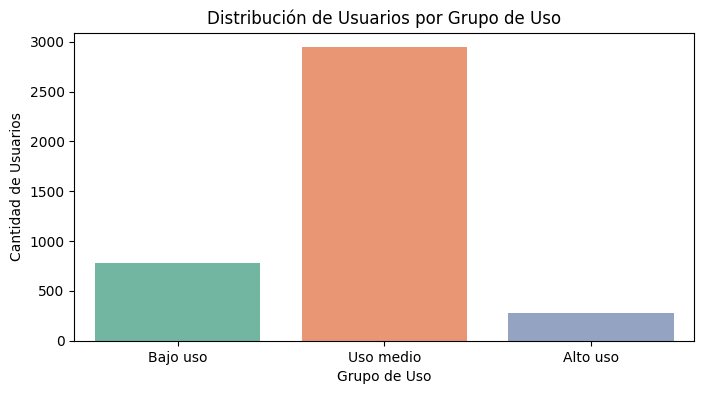

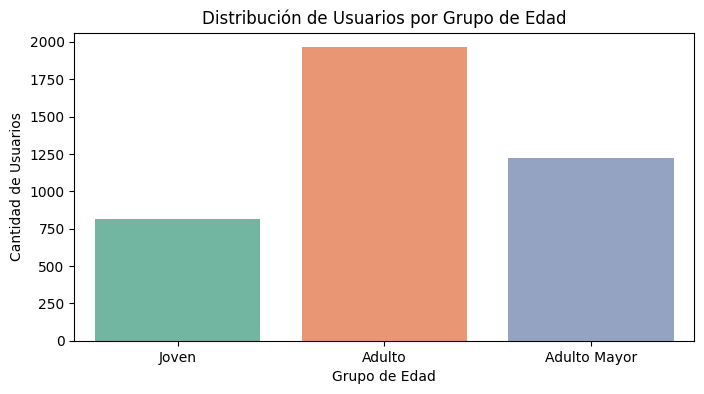

In [23]:
# Visualización de los segmentos por uso
sns.countplot
# Gráfico 1: Distribución por Grupo de Uso
plt.figure(figsize=(8, 4))
sns.countplot(data=user_profile, x='grupo_uso', order=['Bajo uso', 'Uso medio', 'Alto uso'], palette='Set2')
plt.title('Distribución de Usuarios por Grupo de Uso')
plt.xlabel('Grupo de Uso')
plt.ylabel('Cantidad de Usuarios')
plt.show()

# Gráfico 2: Distribución por Grupo de Edad
plt.figure(figsize=(8, 4))
sns.countplot(data=user_profile, x='grupo_edad', order=['Joven', 'Adulto', 'Adulto Mayor'], palette='Set2')
plt.title('Distribución de Usuarios por Grupo de Edad')
plt.xlabel('Grupo de Edad')
plt.ylabel('Cantidad de Usuarios')
plt.show()

plt.show()

In [ ]:
# Visualización de los segmentos por edad
Grupo de Uso: Se observa claramente que la gran mayoría de los clientes se concentra en "Uso medio" (cerca de 3,000 usuarios), seguido por un grupo considerable de "Bajo uso" y una minoría en "Alto uso".

Grupo de Edad: El segmento predominante es el de los "Adultos" (cerca de 2,000 usuarios), seguido por los "Adultos Mayores" y los "Jóvenes".


---
## 🧩Paso 7: Insight Ejecutivo para Stakeholders

🎯 **Objetivo:** Traducir los hallazgos del análisis en conclusiones accionables para el negocio, enfocadas en segmentación, patrones de uso y oportunidades comerciales.

**Preguntas a responder:** 
- ¿Qué problemas tenían originalmemte los datos?¿Qué porcentaje, o cantidad de filas, de esa columna representaban?


- ¿Qué segmentos de clientes identificaste y cómo se comportan según su edad y nivel de uso?  
- ¿Qué segmentos parecen más valiosos para ConnectaTel y por qué?  
- ¿Qué patrones de uso extremo (outliers) encontraste y qué implican para el negocio?


- ¿Qué recomendaciones harías para mejorar la oferta actual de planes o crear nuevos planes basados en los segmentos y patrones detectados?

✍️ **Escribe aquí tu análisis ejecutivo:**
### Análisis ejecutivo

 **Problemas detectados en los datos**
* Valores centinela e inconsistencias en el perfil: Se identificaron valores atípicos imposibles en la columna `age` (como `-999`) y registros con fechas de inscripción futuras en `reg_date` , además de valores de texto faltantes o marcados con `?` en `city`.
* Nulos dependientes de la lógica del negocio : En los registros de consumo (`usage`), los valores nulos en duración corresponden exclusivamente a los eventos de tipo mensaje de texto , mientras que las llamadas  tienen su duración completa. Esto no es un error de sistema, sino parte de la estructura lógica de los datos.


**Segmentos por Edad**
* Predominio del público Adulto: El grupo de Adulto(entre 30 y 59 años) constituye el segmento principal de ConnectaTel, concentrando cerca de 2,000 usuarios.
* Base sólida de Adultos Mayores y Jóvenes: la categoriade Adulto Mayor (60 años o más) ocupa el segundo lugar con alrededor de 1,250 clientes, mientras que los Jóvenes (menores de 30 años) representan aproximadamente 800 usuarios.

 **Segmentos por Nivel de Uso**
* Concentración en consumo moderado: Casi 3,000 clientes (la gran mayoría de la base) pertenecen al segmento de Uso medio, seguidos por cerca de 800 usuarios de Bajo uso y un grupo selecto de aproximadamente 280 clientes en Alto uso.
* **Patrones de uso extremo (Outliers)**: Se detectaron usuarios con consumos muy superiores al promedio (más de 11 mensajes, más de 10 llamadas o llamadas acumuladas de hasta 155 minutos). 

 **Esto sugiere que** los segmentos más valiosos para ConnectaTel son los clientes Adultos de Uso medio por representar el mayor volumen y estabilidad de ingresos recurrente y los usuarios de Alto uso (por su elevado consumo de minutos y mensajes, lo que los convierte en candidatos ideales para planes de mayor margen). Además, la similitud en el comportamiento de consumo entre los planes Básico y Premium indica que muchos usuarios con alto consumo.

 **Recomendaciones**
* estrategia de *Upselling* hacia planes Premium: Dirigir campañas personalizadas a los usuarios de Alto usoy a los clientes en el límite superior de Uso medio que actualmente tienen el plan Básico ofreciéndoles beneficios ilimitados o paquetes de minutos adicionales para incentivar su migración al plan Premium.
* Planes segmentados por perfil demográfico: Diseñar un Plan Senior enfocado en llamadas delarga duración para el fuerte segmento de dultos Mayores, y un Plan Joven / Digital con énfasis en mensajería y datos para atraer y retener a los menores de 30 años.
* Programas de fidelización para Power Users: Crear recompensas o tarifas preferenciales por volumen para los clientes identificados como *outliers* positivos en duración de llamadas, asegurando su retención frente a la competencia.

### Análisis ejecutivo

⚠️ **Problemas detectados en los datos**
Presencia de valores centinela anómalos en la edad (como -999) e inconsistencias de fechas de registro futuras en una fracción menor de los registros iniciales.   Valores nulos lógicos en los registros de consumo, donde la duración de los mensajes de texto es nula por naturaleza del servicio, diferenciándose de las llamadas.



🔍 **Segmentos por Edad**
Adultos: Segmento predominante que concentra cerca de 2,000 usuarios, representando el núcleo de la base de clientes.   Adultos Mayores y Jóvenes: Los adultos mayores ocupan el segundo lugar con 1,250 clientes y los jóvenes suman aproximadamente 800 .



📊 **Segmentos por Nivel de Uso
Consumo moderado: La gran mayoría de los clientes se agrupa en Uso medio (cerca de 3,000 usuarios), seguidos por Bajo uso (800) y Alto uso (280).   Outliers de consumo: Se identificaron  users con un volumen muy elevado de llamadas y mensajes que reflejan una demanda real y activa de la red.   



➡️ Esto sugiere que 
los clientes Adultos de Uso medio son el motor principal de estabilidad e ingresos, mientras que los usuarios de Alto uso son altamente valiosos para campañas de upselling y migración a planes superiores.

💡 **Recomendaciones**
Estrategia de planes: hacer campañas de migración hacia el plan Premium enfocadas en los usuarios con mayor volumen de llamadas y mensajes.   otra opcion  Crear propuestas especializadas, como un plan enfocado en llamadas de larga duración para adultos mayores y planes digitales para jóvenes.   

---

## 🧩Paso 8 Cargar tu notebook y README a GitHub

🎯 **Objetivo:**  
Entregar tu análisis de forma **profesional**, **documentada** y **versionada**, asegurando que cualquier persona pueda revisar, ejecutar y entender tu trabajo.



### Opción A : Subir archivos desde la interfaz de GitHub (UI)

1. Descarga este notebook (`File → Download .ipynb`).  
2. Entra a tu repositorio en GitHub (por ejemplo `telecom-analysis` o `sprint7-final-project`).  
3. Sube tu notebook **Add file → Upload files**.  

---

### Opción B : Guardar directo desde Google Colab

1. Abre tu notebook en Colab.  
2. Ve a **File → Save a copy in GitHub**.  
3. Selecciona el repositorio y la carpeta correcta (ej: `notebooks/`).  
4. Escribe un mensaje de commit claro, por ejemplo:  
    - `feat: add final ConnectaTel analysis`
    - `agregar version final: Análisis ConnectaTel`
5. Verifica en GitHub que el archivo quedó en el lugar correcto y que el historial de commits se mantenga limpio.

---

Agrega un archivo `README.md` que describa de forma clara:
- el objetivo del proyecto,  
- los datasets utilizados,  
- las etapas del análisis realizadas,  
- cómo ejecutar el notebook (por ejemplo, abrirlo en Google Colab),  
- una breve guía de reproducción.
---

Link a repositorio público del proyecto: `LINK a tu repo aquí`